# Proyecto Computacional: Análisis Semántico Latente (LSA) sobre Reseñas de Videojuegos en Steam

**Curso:** Álgebra Lineal Avanzada y Modelamiento (IMT2230) — Pontificia Universidad Católica de Chile  
**Autor:** Benjamín Quijada  

En este notebook aplicamos **Análisis Semántico Latente (LSA)** mediante la **Descomposición en Valores Singulares (SVD)** sobre una matriz término-documento construida a partir de reseñas públicas de videojuegos en Steam, con el objetivo de descubrir estructura temática latente, proyectar documentos y términos en baja dimensión e interpretar tanto los alcances como los límites del método.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Configuración visual reproducible
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
os.makedirs("figures", exist_ok=True)

---
## Paso 1 – Elección y descripción del corpus

El corpus se construyó combinando dos repositorios públicos en GitHub con reseñas reales de usuarios de Steam:
- **`mrafifrbbn/steam-reviews`** ([github.com/mrafifrbbn/steam-reviews](https://github.com/mrafifrbbn/steam-reviews))
- **`mulhod/steam_reviews`** ([github.com/mulhod/steam_reviews](https://github.com/mulhod/steam_reviews))

Para garantizar reproducibilidad exacta y documentos con suficiente contenido léxico, el script [`download_data.py`](download_data.py) extrae **60 reseñas sustanciales en inglés** (entre 280 y 3000 caracteres, con al menos 180 caracteres alfabéticos y deduplicación por prefijo) para cada uno de **4 videojuegos de géneros contrastantes**, conformando un corpus de **$n = 240$ documentos**:

1. **Grand Theft Auto V (GTA V)** (*Action / Open World*)
2. **Dead by Daylight** (*Survival Horror*)
3. **Rocket League** (*Sports / Arcade*)
4. **Counter-Strike** (*Tactical FPS*)

Este corpus es especialmente interesante para LSA porque reúne cuatro experiencias de juego muy distintas (mundo abierto, supervivencia asimétrica, deporte vehicular y *shooter* táctico) junto con temas transversales propios de Steam (rendimiento, compras, comunidad y sistemas anti-trampas).

In [2]:
DATA_PATH = os.path.join("data", "steam_reviews.csv")
if not os.path.exists(DATA_PATH):
    import download_data
    download_data.main()

df = pd.read_csv(DATA_PATH)
df["char_len"] = df["text"].str.len()
df["word_len"] = df["text"].str.split().str.len()

summary = (
    df.groupby(["game", "genre"], sort=False)
    .agg(
        documentos=("doc_id", "count"),
        chars_promedio=("char_len", "mean"),
        palabras_promedio=("word_len", "mean"),
        horas_juego_mediana=("playtime_hours", "median"),
    )
    .round(1)
    .reset_index()
)
print(f"Total de documentos en el corpus: {len(df)}")
summary

Total de documentos en el corpus: 240


,game,genre,documentos,chars_promedio,palabras_promedio,horas_juego_mediana
0,GTA V,Action / Open World,60,698.9,133.4,201.5
1,Dead by Daylight,Survival Horror,60,761.2,140.7,104.5
2,Rocket League,Sports / Arcade,60,572.6,107.7,333.0
3,Counter-Strike,Tactical FPS,60,675.0,119.8,172.0


---
## Paso 2 – Hipótesis inicial

Antes de ejecutar el análisis, planteamos la siguiente hipótesis concreta sobre la estructura del corpus:

> *Dado que los cuatro títulos pertenecen a géneros claramente diferenciados, esperamos que la matriz término-documento exhiba una estructura latente dominada por cuatro grupos temáticos asociados a cada juego: vocabulario de ciudad, misiones, dinero y modo en línea en **GTA V** (*gta, online, rockstar, story, money*); léxico asimétrico de persecución y terror en **Dead by Daylight** (*killer, survivor, perks, repair*); términos de autos y deporte en **Rocket League** (*cars, rocket, football, fly*); y terminología clásica de disparos en **Counter-Strike** (*counter, strike, shooter, fps, aim*). Asimismo, anticipamos que la primera componente singular capturará un eje transversal común a las reseñas de Steam (*play, fun, game, hours*), mientras que las componentes siguientes separarán los géneros, pudiendo existir cercanía entre juegos multijugador cuando las reseñas discuten trampas, baneos o plantillas de evaluación.*

---
## Paso 3 – Preprocesamiento del texto

Para construir un vocabulario limpio e informativo tomamos las siguientes decisiones:

1. **Limpieza previa en descarga**: decodificación de entidades HTML (`&amp;`, etc.) y normalización de espacios.
2. **Normalización a minúsculas** (`lowercase=True`): unifica variantes como `Game` y `game`.
3. **Tokenización alfabética** (`token_pattern=r'(?u)\b[a-zA-Z]{3,}\b'`): conserva solo palabras alfabéticas de al menos 3 letras, descartando números sueltos y puntuación.
4. **Eliminación de *stopwords* en inglés** (`stop_words='english'`): remueve palabras funcionales sin carga temática (*the, and, is, with*).
5. **Filtrado por frecuencia documental** (`min_df=3`, `max_df=0.80`): elimina términos muy raros que aparecen en menos de 3 reseñas (erratas o nombres aislados) y términos demasiado ubicuos presentes en más del 80% de los documentos.
6. **Ponderación TF-IDF con frecuencia sublineal** (`sublinear_tf=True`): escala la frecuencia del término como $1 + \log(\text{tf})$ y pondera por IDF, evitando que reseñas muy largas o repeticiones dominen la norma de las columnas.

Este preprocesamiento es razonable porque reduce el ruido léxico manteniendo un vocabulario compacto pero expresivo para las 240 reseñas.

In [3]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
    min_df=3,
    max_df=0.80,
    sublinear_tf=True,
)

# scikit-learn entrega matriz (documentos x términos)
X_doc_term = vectorizer.fit_transform(df["text"])
terms = np.array(vectorizer.get_feature_names_out())

print(f"Tamaño del vocabulario final (m): {len(terms)} términos")
print(f"Primeros 15 términos del vocabulario: {list(terms[:15])}")

Tamaño del vocabulario final (m): 850 términos
Primeros 15 términos del vocabulario: ['abilities', 'able', 'absolute', 'absolutely', 'account', 'action', 'active', 'actually', 'add', 'added', 'addicting', 'addictive', 'adding', 'addition', 'advantage']


---
## Paso 4 – Construcción de la matriz textual $A$

En LSA, la matriz término-documento se define como $A \in \mathbb{R}^{m \times n}$, donde las **filas** ($m$) corresponden a los términos del vocabulario y las **columnas** ($n$) representan los documentos del corpus. Como `TfidfVectorizer` entrega una matriz dispersa de tamaño $n \times m$, la transponemos y convertimos a arreglo denso para su descomposición espectral.

In [4]:
A = X_doc_term.T.toarray()  # m x n
m, n = A.shape
density = np.count_nonzero(A) / A.size
frob_norm = np.linalg.norm(A, "fro")

print(f"Dimensiones de A: {m} términos x {n} documentos")
print(f"Densidad de entradas no nulas: {density:.2%} (esparsidad: {1 - density:.2%})")
print(f"Norma de Frobenius ||A||_F: {frob_norm:.4f}")

Dimensiones de A: 850 términos x 240 documentos
Densidad de entradas no nulas: 3.53% (esparsidad: 96.47%)
Norma de Frobenius ||A||_F: 15.4919


---
## Paso 5 – Cálculo de la SVD

Calculamos la Descomposición en Valores Singulares (SVD) reducida (económica) de $A$:

$$A = U \Sigma V^T$$

mediante `np.linalg.svd(A, full_matrices=False)`. Con `full_matrices=False`, dado que $r = \min(m, n) = 240$, obtenemos:
- $U \in \mathbb{R}^{m \times r}$: vectores singulares por la izquierda (espacio de términos).
- $\Sigma = \operatorname{diag}(\sigma_1, \dots, \sigma_r) \in \mathbb{R}^{r \times r}$: valores singulares ordenados $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_r \ge 0$.
- $V^T \in \mathbb{R}^{r \times n}$: transpuesta de los vectores singulares por la derecha (espacio de documentos).

In [5]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
V = Vt.T

print(f"Dimensión de U:   {U.shape}")
print(f"Dimensión de s:   {s.shape} (valores singulares)")
print(f"Dimensión de V^T: {Vt.shape}")

# Verificación numérica de la descomposición
A_reconstructed = (U * s) @ Vt
recon_error = np.linalg.norm(A - A_reconstructed, "fro")
print(f"Error de reconstrucción ||A - U*Sigma*V^T||_F: {recon_error:.2e}")

Dimensión de U:   (850, 240)
Dimensión de s:   (240,) (valores singulares)
Dimensión de V^T: (240, 240)
Error de reconstrucción ||A - U*Sigma*V^T||_F: 4.96e-14


---
## Paso 6 – Análisis de valores singulares

Analizamos el espectro de valores singulares $\sigma_i$ y la fracción de energía (norma de Frobenius al cuadrado) acumulada por las primeras $k$ componentes:

$$E(k) = \frac{\sum_{i=1}^{k} \sigma_i^2}{\sum_{i=1}^{r} \sigma_i^2}$$

Primeros 12 valores singulares: [3.756 2.094 1.931 1.783 1.642 1.58  1.55  1.529 1.515 1.498 1.486 1.474]
k =   2 -> energía acumulada: 7.71%
k =   3 -> energía acumulada: 9.26%
k =   4 -> energía acumulada: 10.58%
k =  10 -> energía acumulada: 16.61%
k =  20 -> energía acumulada: 25.19%
k =  40 -> energía acumulada: 39.46%
k =  80 -> energía acumulada: 60.91%
k = 120 -> energía acumulada: 76.39%


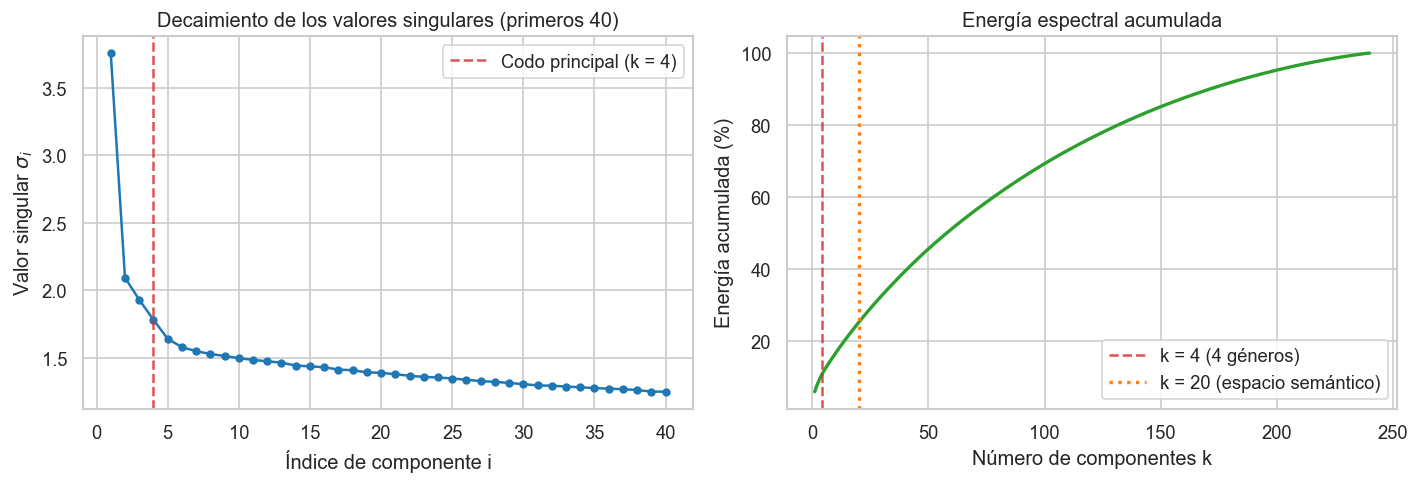

In [6]:
energy = s**2
cum_energy = np.cumsum(energy) / np.sum(energy)

print("Primeros 12 valores singulares:", np.round(s[:12], 3))
for k_val in [2, 3, 4, 10, 20, 40, 80, 120]:
    print(f"k = {k_val:3d} -> energía acumulada: {cum_energy[k_val - 1]:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Gráfico 1: Decaimiento de los primeros 40 valores singulares
axes[0].plot(range(1, 41), s[:40], marker="o", markersize=4, color="#1f77b4")
axes[0].axvline(4, color="#d62728", linestyle="--", alpha=0.8, label="Codo principal (k = 4)")
axes[0].set_title("Decaimiento de los valores singulares (primeros 40)")
axes[0].set_xlabel("Índice de componente i")
axes[0].set_ylabel(r"Valor singular $\sigma_i$")
axes[0].legend()

# Gráfico 2: Energía acumulada
axes[1].plot(range(1, len(s) + 1), cum_energy * 100, color="#2ca02c", linewidth=2)
axes[1].axvline(4, color="#d62728", linestyle="--", alpha=0.8, label="k = 4 (4 géneros)")
axes[1].axvline(20, color="#ff7f0e", linestyle=":", linewidth=2, label="k = 20 (espacio semántico)")
axes[1].set_title("Energía espectral acumulada")
axes[1].set_xlabel("Número de componentes k")
axes[1].set_ylabel("Energía acumulada (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/singular_values.png", dpi=200, bbox_inches="tight")
plt.show()

**Elección y justificación de $k$:**  
El salto más grande ocurre entre $\sigma_1 = 3.756$ y $\sigma_2 = 2.094$ (diferencia $1.66$), lo que corresponde al eje común del vocabulario de reseñas. Después, $\sigma_2, \sigma_3, \sigma_4$ siguen bajando con diferencias de $\approx 0.14$–$0.16$, y **a partir de $\sigma_5 = 1.642$ la curva se aplana** (las diferencias caen a $0.06$ y luego a $\approx 0.02$–$0.03$). El codo no es abrupto, pero sí sugiere que las primeras 4 componentes se separan de una cola plana de ruido, lo cual es coherente con tener **4 juegos distintos** (1 eje común + 3 direcciones de contraste entre 4 grupos). Como las matrices TF-IDF de texto son dispersas y de rango alto, $k = 4$ retiene solo el $10.58\%$ de la energía. Por eso usamos $k = 4$ para interpretar temas y **$k = 20$** ($25.19\%$ de la energía) para las búsquedas de similitud, buscando un equilibrio entre conservar matices y descartar la cola ruidosa. Esta elección de $k = 20$ es un criterio práctico, no algo que salga directamente del gráfico.

---
## Paso 7 – Representación de documentos y términos en baja dimensión

Para proyectar en 2D siguiendo exactamente la geometría de la SVD:

- **Documentos (columnas de $A$):** elegimos un par de vectores singulares por la izquierda $(u_a, u_b)$ y proyectamos cada columna $A_{:,d}$ sobre $\operatorname{Span}(u_a, u_b)$. Gracias a la ortonormalidad de $U$ y a que $A = U\Sigma V^T$, las coordenadas de proyección son:
  $$\big(u_a^T A_{:,d},\; u_b^T A_{:,d}\big) = \big(\sigma_a V_{d,a},\; \sigma_b V_{d,b}\big)$$

- **Términos (filas de $A$):** elegimos un par de vectores singulares por la derecha $(v_a, v_b)$ y proyectamos cada fila $A_{t,:}$ sobre $\operatorname{Span}(v_a, v_b)$. Sus coordenadas en la base $(v_a, v_b)$ son:
  $$\big(A_{t,:} v_a,\; A_{t,:} v_b\big) = \big(\sigma_a U_{t,a},\; \sigma_b U_{t,b}\big)$$

En matrices no negativas ($A \ge 0$), la primera componente $(u_1, v_1)$ suele capturar el eje promedio común a todo el corpus (teorema de Perron-Frobenius). Por ello, compararemos la proyección en **$(1, 2)$** frente a **$(2, 3)$**, que elimina ese modo común y revela la separación temática entre géneros.

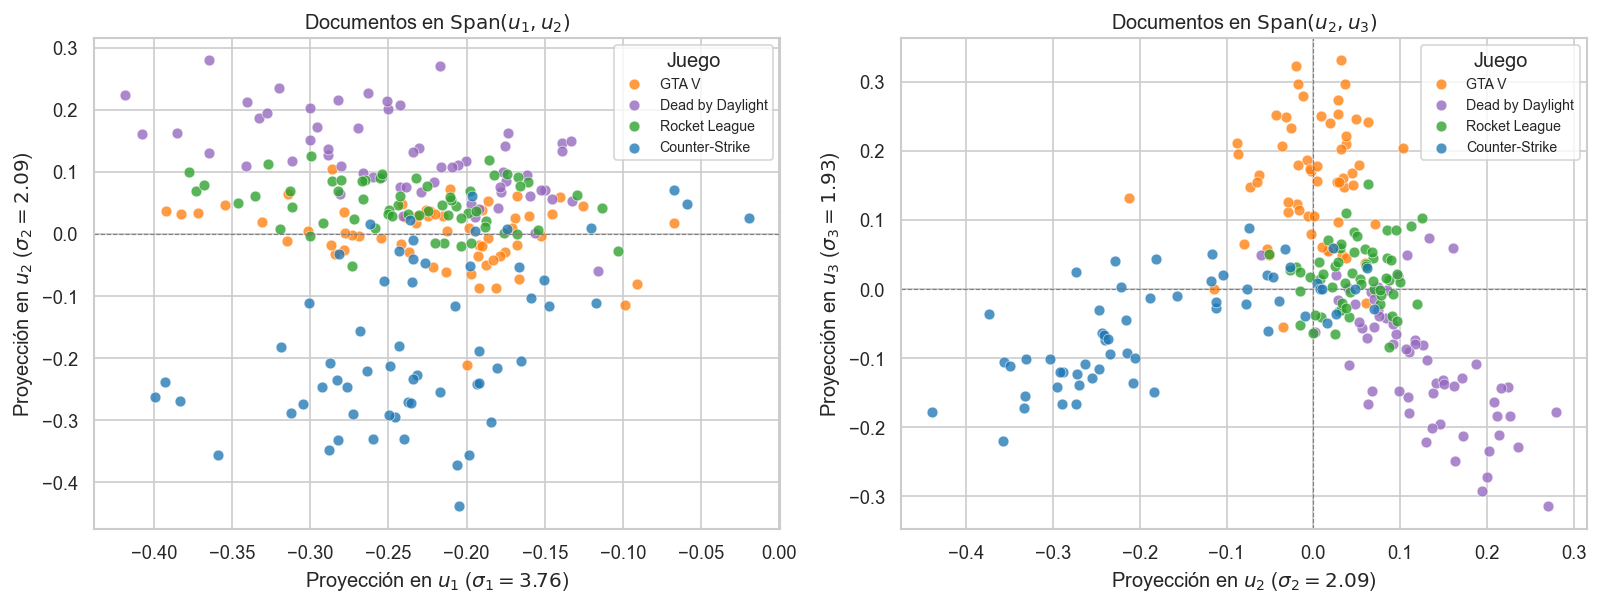

In [7]:
def project_documents(U, s, Vt, a_idx: int, b_idx: int) -> np.ndarray:
    """Proyecta columnas de A sobre Span(u_a, u_b): coordenadas u^T A = sigma * v^T."""
    U_sub = U[:, [a_idx, b_idx]]
    return (U_sub.T @ A).T  # shape (n, 2)


def project_terms(U, s, Vt, a_idx: int, b_idx: int) -> np.ndarray:
    """Proyecta filas de A sobre Span(v_a, v_b): coordenadas A v = sigma * u."""
    V_sub = Vt[[a_idx, b_idx], :].T
    return A @ V_sub  # shape (m, 2)


docs_12 = project_documents(U, s, Vt, 0, 1)
docs_23 = project_documents(U, s, Vt, 1, 2)
terms_23 = project_terms(U, s, Vt, 1, 2)

# Visualización 2D de documentos: (u1, u2) vs (u2, u3)
palette = {
    "GTA V": "#ff7f0e",
    "Dead by Daylight": "#9467bd",
    "Rocket League": "#2ca02c",
    "Counter-Strike": "#1f77b4",
}

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

for game, color in palette.items():
    mask = df["game"] == game
    axes[0].scatter(
        docs_12[mask, 0], docs_12[mask, 1],
        label=game, color=color, alpha=0.78, s=42, edgecolors="white", linewidth=0.4
    )
    axes[1].scatter(
        docs_23[mask, 0], docs_23[mask, 1],
        label=game, color=color, alpha=0.78, s=42, edgecolors="white", linewidth=0.4
    )

axes[0].axhline(0, color="gray", lw=0.7, ls="--")
axes[0].axvline(0, color="gray", lw=0.7, ls="--")
axes[0].set_title(r"Documentos en $\operatorname{Span}(u_1, u_2)$")
axes[0].set_xlabel(rf"Proyección en $u_1$ ($\sigma_1 = {s[0]:.2f}$)")
axes[0].set_ylabel(rf"Proyección en $u_2$ ($\sigma_2 = {s[1]:.2f}$)")
axes[0].legend(title="Juego", fontsize=8.5)

axes[1].axhline(0, color="gray", lw=0.7, ls="--")
axes[1].axvline(0, color="gray", lw=0.7, ls="--")
axes[1].set_title(r"Documentos en $\operatorname{Span}(u_2, u_3)$")
axes[1].set_xlabel(rf"Proyección en $u_2$ ($\sigma_2 = {s[1]:.2f}$)")
axes[1].set_ylabel(rf"Proyección en $u_3$ ($\sigma_3 = {s[2]:.2f}$)")
axes[1].legend(title="Juego", fontsize=8.5)

plt.tight_layout()
plt.savefig("figures/docs_2d.png", dpi=200, bbox_inches="tight")
plt.show()

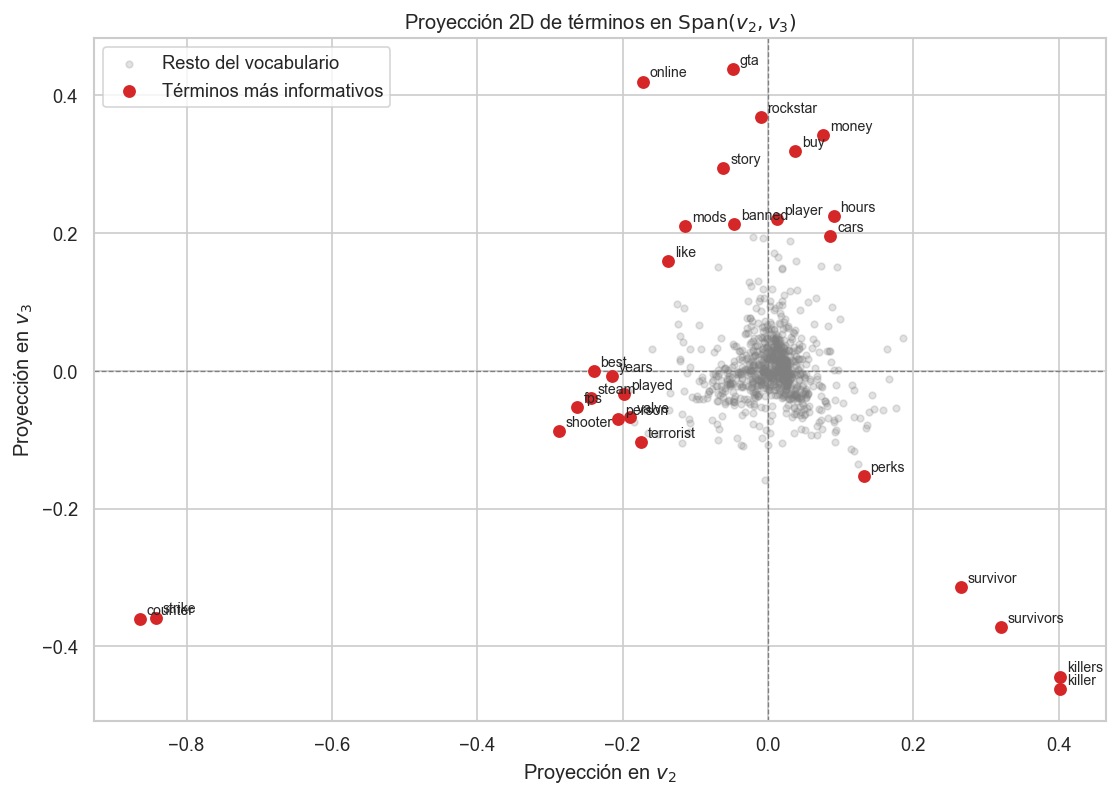

In [8]:
# Visualización 2D de términos en Span(v2, v3)
norms_23 = np.linalg.norm(terms_23, axis=1)
top_term_idx = np.argsort(norms_23)[-28:]

fig, ax = plt.subplots(figsize=(9.5, 6.8))
ax.scatter(terms_23[:, 0], terms_23[:, 1], alpha=0.22, s=16, color="#7f7f7f", label="Resto del vocabulario")
ax.scatter(terms_23[top_term_idx, 0], terms_23[top_term_idx, 1], color="#d62728", s=45, zorder=3, label="Términos más informativos")

for idx in top_term_idx:
    x, y = terms_23[idx, 0], terms_23[idx, 1]
    ax.annotate(
        terms[idx],
        (x, y),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="medium",
    )

ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.axvline(0, color="gray", lw=0.8, ls="--")
ax.set_title(r"Proyección 2D de términos en $\operatorname{Span}(v_2, v_3)$")
ax.set_xlabel(r"Proyección en $v_2$")
ax.set_ylabel(r"Proyección en $v_3$")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("figures/terms_2d.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación de las proyecciones 2D:**  
- En $\operatorname{Span}(u_1, u_2)$, todas las reseñas se concentran en el semiplano izquierdo ($u_1 < 0$) porque $u_1$ representa el uso general del vocabulario común de reseñas de videojuegos en Steam.
- Al pasar a $\operatorname{Span}(u_2, u_3)$ (y su contraparte de términos $\operatorname{Span}(v_2, v_3)$), la estructura por género emerge con claridad:
  - **Dead by Daylight** se proyecta hacia la derecha ($u_2 > 0, u_3 < 0$), alineado con términos como *killer, killers, survivor, survivors, dlc*.
  - **Counter-Strike** se ubica hacia la izquierda-abajo ($u_2 < 0, u_3 < 0$), alineado con *counter, strike, shooter, fps, steam*.
  - **GTA V** asciende en la componente 3 ($u_3 > 0$), dominado por *gta, online, rockstar, money, story*.
  - **Rocket League** queda cerca del origen en este plano y se superpone en parte con los demás; se diferencia mejor en la cuarta componente ($u_4 > 0$), como se ve en el paso siguiente. Como referencia, asignar cada documento al centroide de su juego más cercano acierta en un $\approx 78\%$ de los casos usando $(u_2, u_3)$ y en un $\approx 82\%$ al agregar $u_4$. La separación es clara, pero no perfecta.
  - *Nota:* los signos de los vectores singulares son arbitrarios (cambiar $u_i \to -u_i$ y $v_i \to -v_i$ deja $A$ igual), así que lo que importa es la posición relativa de los grupos, no si quedan a la izquierda o a la derecha.

---
## Paso 8 – Exploración semántica

Exploramos tres ejemplos concretos usando la representación reducida de rango $k = 20$ (matrices $U_k \Sigma_k$ para términos y $\Sigma_k V_k^T$ para documentos):

1. **Significado temático de las componentes singulares ($u_2, u_3, u_4$).**
2. **Términos semánticamente cercanos** mediante similitud coseno en el espacio latente de dimensión $k = 20$.
3. **Documentos cercanos y conexiones entre juegos distintos** en el espacio reducido.

In [9]:
# 1. Top términos positivos y negativos en las componentes 2, 3 y 4
print("=== Ejemplo 1: Términos extremos por componente singular ===")
for comp in [1, 2, 3]:  # índices 0-based: Comp 2, Comp 3, Comp 4
    pos = terms[np.argsort(U[:, comp])[-7:][::-1]]
    neg = terms[np.argsort(U[:, comp])[:7]]
    print(f"Componente {comp + 1} (sigma = {s[comp]:.3f}):")
    print(f"  (+) {', '.join(pos)}")
    print(f"  (-) {', '.join(neg)}")

=== Ejemplo 1: Términos extremos por componente singular ===
Componente 2 (sigma = 2.094):
  (+) killers, killer, survivors, survivor, fun, make, dlc
  (-) counter, strike, shooter, fps, steam, best, years
Componente 3 (sigma = 1.931):
  (+) gta, online, rockstar, money, buy, story, hours
  (-) killer, killers, survivors, counter, strike, survivor, map
Componente 4 (sigma = 1.783):
  (+) cars, rocket, hours, league, great, really, football
  (-) killer, rockstar, online, killers, survivors, survivor, banned


In [10]:
# 2. Términos más cercanos en el espacio LSA reducido (k = 20)
k = 20
term_emb = U[:, :k] * s[:k]  # m x k

def nearest_terms(query: str, top_n: int = 6):
    if query not in vectorizer.vocabulary_:
        print(f"'{query}' no está en el vocabulario.")
        return
    q_idx = vectorizer.vocabulary_[query]
    sims = cosine_similarity(term_emb[q_idx:q_idx+1], term_emb)[0]
    best = np.argsort(sims)[::-1][1 : top_n + 1]
    print(f"Vecinos de '{query}': " + ", ".join(f"{terms[i]} ({sims[i]:.2f})" for i in best))

print("\n=== Ejemplo 2: Palabras cercanas en dimensión k = 20 ===")
for w in ["rockstar", "survivor", "shooter", "cars"]:
    nearest_terms(w)


=== Ejemplo 2: Palabras cercanas en dimensión k = 20 ===
Vecinos de 'rockstar': modder (0.86), ban (0.85), support (0.83), hacker (0.75), card (0.74), shark (0.73)
Vecinos de 'survivor': killer (0.95), survivors (0.88), unbalanced (0.87), pallets (0.85), repair (0.84), killers (0.84)
Vecinos de 'shooter': search (0.91), person (0.87), simplistic (0.86), modern (0.82), version (0.81), popular (0.80)
Vecinos de 'cars': football (0.81), fly (0.80), hours (0.77), flying (0.76), car (0.75), wish (0.72)


In [11]:
# 3. Documentos cercanos en el espacio LSA reducido (k = 20)
doc_emb = (s[:k, None] * Vt[:k, :]).T  # n x k
doc_sims = cosine_similarity(doc_emb)
np.fill_diagonal(doc_sims, -1.0)

games_arr = df["game"].to_numpy(dtype=str)
same_mask = games_arr[:, None] == games_arr[None, :]
diff_mask = ~same_mask

i_same, j_same = np.unravel_index(np.argmax(np.where(same_mask, doc_sims, -1)), doc_sims.shape)
i_diff, j_diff = np.unravel_index(np.argmax(np.where(diff_mask, doc_sims, -1)), doc_sims.shape)

print("\n=== Ejemplo 3: Pares de documentos cercanos ===")
print(f"[Mismo juego] {df.loc[i_same, 'doc_id']} ({df.loc[i_same, 'game']}) <-> "
      f"{df.loc[j_same, 'doc_id']} ({df.loc[j_same, 'game']}) | sim = {doc_sims[i_same, j_same]:.3f}")
print("  Doc A:", df.loc[i_same, "text"][:230], "...")
print("  Doc B:", df.loc[j_same, "text"][:230], "...")

print(f"\n[Juegos distintos] {df.loc[i_diff, 'doc_id']} ({df.loc[i_diff, 'game']}) <-> "
      f"{df.loc[j_diff, 'doc_id']} ({df.loc[j_diff, 'game']}) | sim = {doc_sims[i_diff, j_diff]:.3f}")
print("  Doc A:", df.loc[i_diff, "text"][:230], "...")
print("  Doc B:", df.loc[j_diff, "text"][:230], "...")


=== Ejemplo 3: Pares de documentos cercanos ===
[Mismo juego] rocket_league_09 (Rocket League) <-> rocket_league_19 (Rocket League) | sim = 0.982
  Doc A: Kids Everyone Casual players Pro players Graphics Potato Really bad Bad OK Good Beautiful (with few mods) Masterpiece Price / quality Full price Wait for sale Average Refund it if you can Dont do it Free Requirments 90' PC Minimum ...
  Doc B: Audience Kids Everyone Casual players Pro players Graphics Potato Really bad Bad OK Good Beautiful Masterpiece Price/quality Full price Wait for sale Average Refund it if you can Don't do it Requirments 90' PC Minimum Medium Fast  ...

[Juegos distintos] gta_v_51 (GTA V) <-> counter_strike_28 (Counter-Strike) | sim = 0.853
  Doc A: I have been playing GTAV & GTA Online in PC for about 2 days nowand surprisingly I haven't got banned for no reason yetbut my friend got banned for no reason (he got banned because of Steam FPS Counter)but still great game.For "Ho ...
  Doc B: I got banned from this

**Interpretación de los ejemplos semánticos:**
- **Componentes temáticas:** La componente 2 contrasta *Dead by Daylight* (`killers, killer, survivors, survivor, dlc`) frente a *Counter-Strike* (`counter, strike, shooter, fps, steam`). La componente 3 aísla el universo de *GTA V* (`gta, online, rockstar, money, story`), y la componente 4 destaca con claridad el dominio de *Rocket League* (`cars, rocket, league, football`).
- **Términos cercanos:** El espacio reducido de rango $k = 20$ recupera relaciones específicas de la experiencia de cada comunidad: `survivor` se asocia con `killer (0.95), unbalanced (0.87), pallets (0.85), repair (0.84)` (mecánicas propias de *Dead by Daylight*); `rockstar` aparece junto a `modder (0.86), ban (0.85), support (0.83), card (0.74), shark (0.73)` (controversias de *GTA Online* y *Shark Cards*); y `cars` se vincula con `football (0.81), fly (0.80), flying (0.76)` (la premisa de *Rocket League*).
- **Documentos cercanos:** Dentro de *Rocket League*, el par más similar (`sim = 0.982`) corresponde a reseñas con formato de plantilla/evaluación por categorías (*Graphics, Price/quality, Requirements*), que LSA agrupa automáticamente por compartir estructura léxica. Entre juegos distintos, el par más cercano (`gta_v_51` y `counter_strike_28`, `sim = 0.853`) conecta **GTA V** con **Counter-Strike** porque ambos jugadores relatan haber recibido un **baneo injusto** (*banned, reason, account, hacks*), ilustrando cómo LSA detecta temáticas transversales más allá del título del juego.

---
## Paso 9 – Discusión, limitaciones y conclusiones

### Contraste con la hipótesis inicial
La hipótesis inicial **se cumple en gran medida**: sin usar las etiquetas, la SVD recupera la estructura de los cuatro juegos. El espectro se aplana después de las primeras 4 componentes, y las componentes $2, 3$ y $4$ separan documentos y términos por juego (con un $\approx 82\%$ de acierto por centroide en $(u_2, u_3, u_4)$). Aun así, hay superposición, sobre todo en *Rocket League* y en reseñas genéricas. Además, la componente $1$ efectivamente actúa como eje común del lenguaje general de reseñas.

### Resultados esperados e inesperados
- **Esperado:** Cada juego activa un subespacio propio con sus términos característicos (*killer/survivor* en *Dead by Daylight*, *cars/football* en *Rocket League*, *shooter/fps* en *Counter-Strike*, *gta/online/story* en *GTA V*).
- **Inesperado (hallazgos del corpus):** En *GTA V*, un eje muy fuerte de discusión no es solo el modo historia, sino las quejas sobre **baneos, *modders* y *Shark Cards* en GTA Online**; esto incluso genera un puente semántico con reseñas de *Counter-Strike* centradas en **baneos de VAC** (`sim = 0.853`). Asimismo, la presencia de plantillas tipo *checklist* en Steam explica similitudes muy altas entre reseñas con poco texto narrativo original.

### Límites del método (LSA/SVD) y del corpus
1. **Bolsa de palabras (Bag-of-Words):** TF-IDF ignora el orden de las palabras, las negaciones (*"not recommended"*) y el sarcasmo o humor tan habitual en Steam.
2. **Linealidad y polisemia:** La SVD solo captura relaciones lineales de co-ocurrencia, por lo que términos ambiguos como *hacker*, *mod* o *server* pueden mezclar contextos entre juegos multijugador (*GTA Online* y *Counter-Strike*).
3. **Límites del corpus:** Aunque 240 documentos en inglés superan ampliamente el mínimo de 50, representan una muestra acotada y sensible a reseñas tipo plantilla. Por ello, LSA es ideal como brújula exploratoria, pero no reemplaza la lectura directa de las reseñas.